# Office 12 (sensor 1247)

### Pre-processing

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import datetime
import holidays

file_path = "../data/office_temps_combined_and_aligned.csv"

try:
  temperatures = pd.read_csv(file_path)

except FileNotFoundError:
  print(f"File not found: {file_path}")
except Exception as e:
  print(f"An error occurred while loading the file: {e}")

In [2]:
temperatures = temperatures.rename(columns={'Unnamed: 0': 'timestamp'})
temperatures['timestamp'] = pd.to_datetime(temperatures['timestamp'])
temperatures = temperatures.set_index('timestamp')
temperatures = temperatures[['o12_full']]
temperatures = temperatures.dropna()
print(temperatures.head())
print(temperatures.tail())
print(temperatures.shape)

                     o12_full
timestamp                    
2025-03-13 12:00:00      21.4
2025-03-13 13:00:00      21.8
2025-03-13 14:00:00      22.0
2025-03-13 15:00:00      22.1
2025-03-13 16:00:00      22.2
                     o12_full
timestamp                    
2025-11-21 13:00:00      23.0
2025-11-21 14:00:00      23.2
2025-11-21 15:00:00      23.2
2025-11-21 16:00:00      23.0
2025-11-21 17:00:00      22.8
(6078, 1)


In [3]:
file_path = "../data/consumption12.xlsx"

try:
  df = pd.read_excel(file_path)
  print(df.head(-3))

except FileNotFoundError:
  print(f"File not found: {file_path}")
except Exception as e:
  print(f"An error occurred while loading the file: {e}")

               timestamp  consumption  Στήλη 1  Στήλη 2  Στήλη 3  Στήλη 4
0    2024-11-04 01:00:00          NaN      NaN      NaN      NaN      NaN
1    2024-11-04 02:00:00       148.28      NaN      NaN      NaN      NaN
2    2024-11-04 03:00:00       148.22      NaN      NaN      NaN      NaN
3    2024-11-04 04:00:00       148.77      NaN      NaN      NaN      NaN
4    2024-11-04 05:00:00       144.94      NaN      NaN      NaN      NaN
...                  ...          ...      ...      ...      ...      ...
8243 2025-11-15 02:00:00         0.00      NaN      NaN      NaN      NaN
8244 2025-11-15 03:00:00         0.00      NaN      NaN      NaN      NaN
8245 2025-11-15 04:00:00         0.00      NaN      NaN      NaN      NaN
8246 2025-11-15 05:00:00         0.00      NaN      NaN      NaN      NaN
8247 2025-11-15 06:00:00         0.00      NaN      NaN      NaN      NaN

[8248 rows x 6 columns]


In [4]:
df = df[['timestamp', 'consumption']]
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.drop(0)
print(df.dtypes)
print("There are ",len(df), " entries")
df

timestamp      datetime64[us]
consumption           float64
dtype: object
There are  8250  entries


,timestamp,consumption
1,2024-11-04 02:00:00,148.28
2,2024-11-04 03:00:00,148.22
3,2024-11-04 04:00:00,148.77
4,2024-11-04 05:00:00,144.94
5,2024-11-04 06:00:00,140.02
...,...,...
8246,2025-11-15 05:00:00,0.00
8247,2025-11-15 06:00:00,0.00
8248,2025-11-15 07:00:00,0.00
8249,2025-11-15 08:00:00,0.00


In [5]:
duplicate_timestamps = df[df.index.duplicated(keep=False)].index.unique()

if not duplicate_timestamps.empty:
    print(f"Duplicate timestamps found: {duplicate_timestamps.tolist()}")
    df = df.groupby(df.index).mean(numeric_only=True) # Merge by averaging consumption
    print("Duplicate timestamps have been merged by averaging their consumption values.")
else:
    print("No duplicate timestamps found.")

print("Current DataFrame shape after checking for duplicates:", df.shape)

No duplicate timestamps found.
Current DataFrame shape after checking for duplicates: (8250, 2)


### Ορισμός του timestamp ως index. Ορισμός της συχνότητας σε επίπεδο ώρας και εντοπισμός των outliers

In [6]:
import holidays

df = df.set_index('timestamp')
df = df.resample('h').mean()
missing = df[df['consumption'].isna()]
df['day_name'] = df.index.day_name()
df['month'] = df.index.month_name()

years = df.index.year.unique()
gr_holidays = holidays.Greece(years=years)

missing_on_holidays = missing[
    pd.Series(missing.index.date, index=missing.index).isin(gr_holidays)
]
num_missing_holidays = len(missing_on_holidays)

print(f"There are {len(df)} entries, including {len(missing)} who are NaN")
print(
    f"Out of the missing entries, {num_missing_holidays} fall on a Greek public holiday."
)

There are 9032 entries, including 782 who are NaN
Out of the missing entries, 48 fall on a Greek public holiday.


In [7]:
def missing_value_summary(df, columns):
    rows = []
    for col in columns:
        series = df[col]
        valid = series.dropna()

        if valid.empty:
            rows.append({'column': col, 'start': None, 'end': None, 'length': 0, 'missing': 0, 'missing_pct': 0.0})
            continue

        start = valid.index.min()
        end = valid.index.max()
        window = series.loc[start:end]
        length = len(window)
        missing = int(window.isna().sum())
        missing_pct = round((missing / length) * 100, 2) if length > 0 else 0.0

        rows.append({'column': col, 'start': start, 'end': end, 'length': length, 'missing': missing, 'missing_pct': missing_pct})

    return pd.DataFrame(rows).set_index('column')

consumption_summary = missing_value_summary(df, ['consumption'])
consumption_summary

,start,end,length,missing,missing_pct
column,,,,,
consumption,2024-11-04 02:00:00,2025-11-15 09:00:00,9032,782,8.66


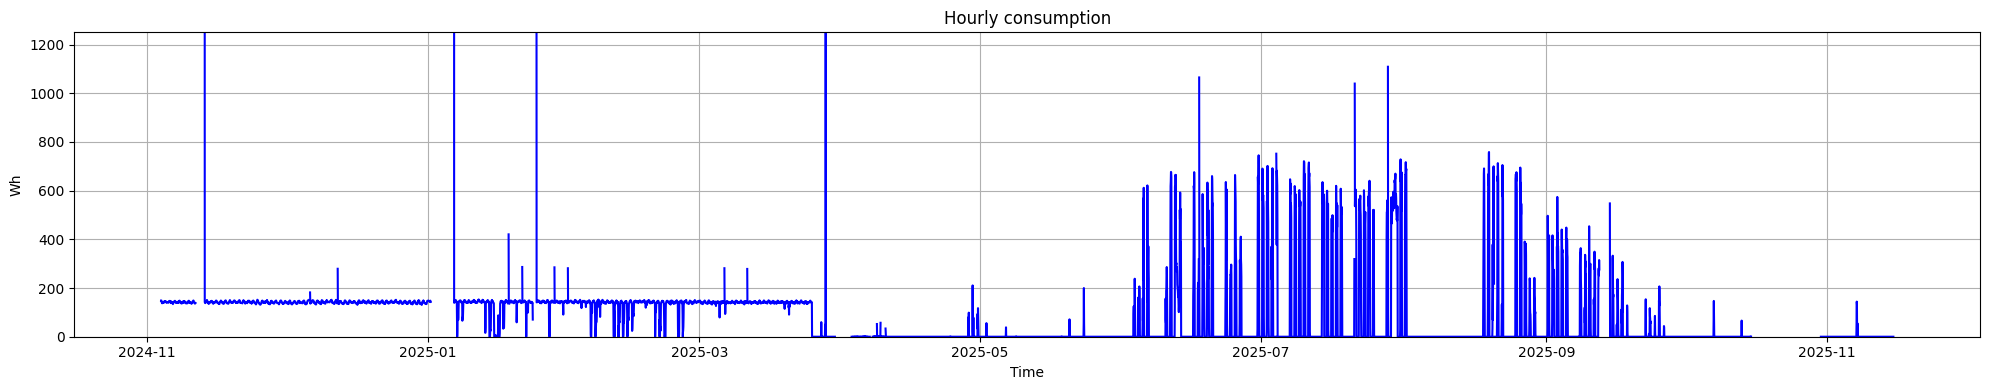

In [8]:
plt.figure(figsize=(20, 4))

plt.plot(df.index, df['consumption'], color='blue')
plt.title("Hourly consumption")
plt.xlabel("Time")
plt.ylabel("Wh")
plt.grid(True)
#plt.xlim(pd.to_datetime('2025-06-01 00:00:00'), pd.to_datetime('2025-08-01 00:00:00'))
plt.ylim(0, 1250)

plt.tight_layout()
plt.show()

### Alignment with indoor temperature

In [9]:
#Add a column for temperature
df_merged = df.join(temperatures, how='left')

later_start_date = max(df.index.min(), temperatures.index.min())
df = df_merged[df_merged.index >= later_start_date]
df = df.rename(columns={'o12_full': 'temperature'})

print(f"Original df start date: {df_merged.index.min()}")
print(f"Temperatures start date: {temperatures.index.min()}")
print(f"New df start date: {df.index.min()}")
print("Merged DataFrame head:")
print(df.head())
print(df.tail())
print(df.shape)

Original df start date: 2024-11-04 02:00:00
Temperatures start date: 2025-03-13 12:00:00
New df start date: 2025-03-13 12:00:00
Merged DataFrame head:
                     consumption  day_name  month  temperature
timestamp                                                     
2025-03-13 12:00:00       136.25  Thursday  March         21.4
2025-03-13 13:00:00       136.66  Thursday  March         21.8
2025-03-13 14:00:00       137.70  Thursday  March         22.0
2025-03-13 15:00:00       138.37  Thursday  March         22.1
2025-03-13 16:00:00       141.35  Thursday  March         22.2
                     consumption  day_name     month  temperature
timestamp                                                        
2025-11-15 05:00:00          0.0  Saturday  November         19.9
2025-11-15 06:00:00          0.0  Saturday  November         19.8
2025-11-15 07:00:00          0.0  Saturday  November         19.8
2025-11-15 08:00:00          0.0  Saturday  November         19.9
2025-11-15 0

In [10]:
df

,consumption,day_name,month,temperature
timestamp,,,,
2025-03-13 12:00:00,136.25,Thursday,March,21.4
2025-03-13 13:00:00,136.66,Thursday,March,21.8
2025-03-13 14:00:00,137.70,Thursday,March,22.0
2025-03-13 15:00:00,138.37,Thursday,March,22.1
2025-03-13 16:00:00,141.35,Thursday,March,22.2
...,...,...,...,...
2025-11-15 05:00:00,0.00,Saturday,November,19.9
2025-11-15 06:00:00,0.00,Saturday,November,19.8
2025-11-15 07:00:00,0.00,Saturday,November,19.8


### Key intervals with missing values

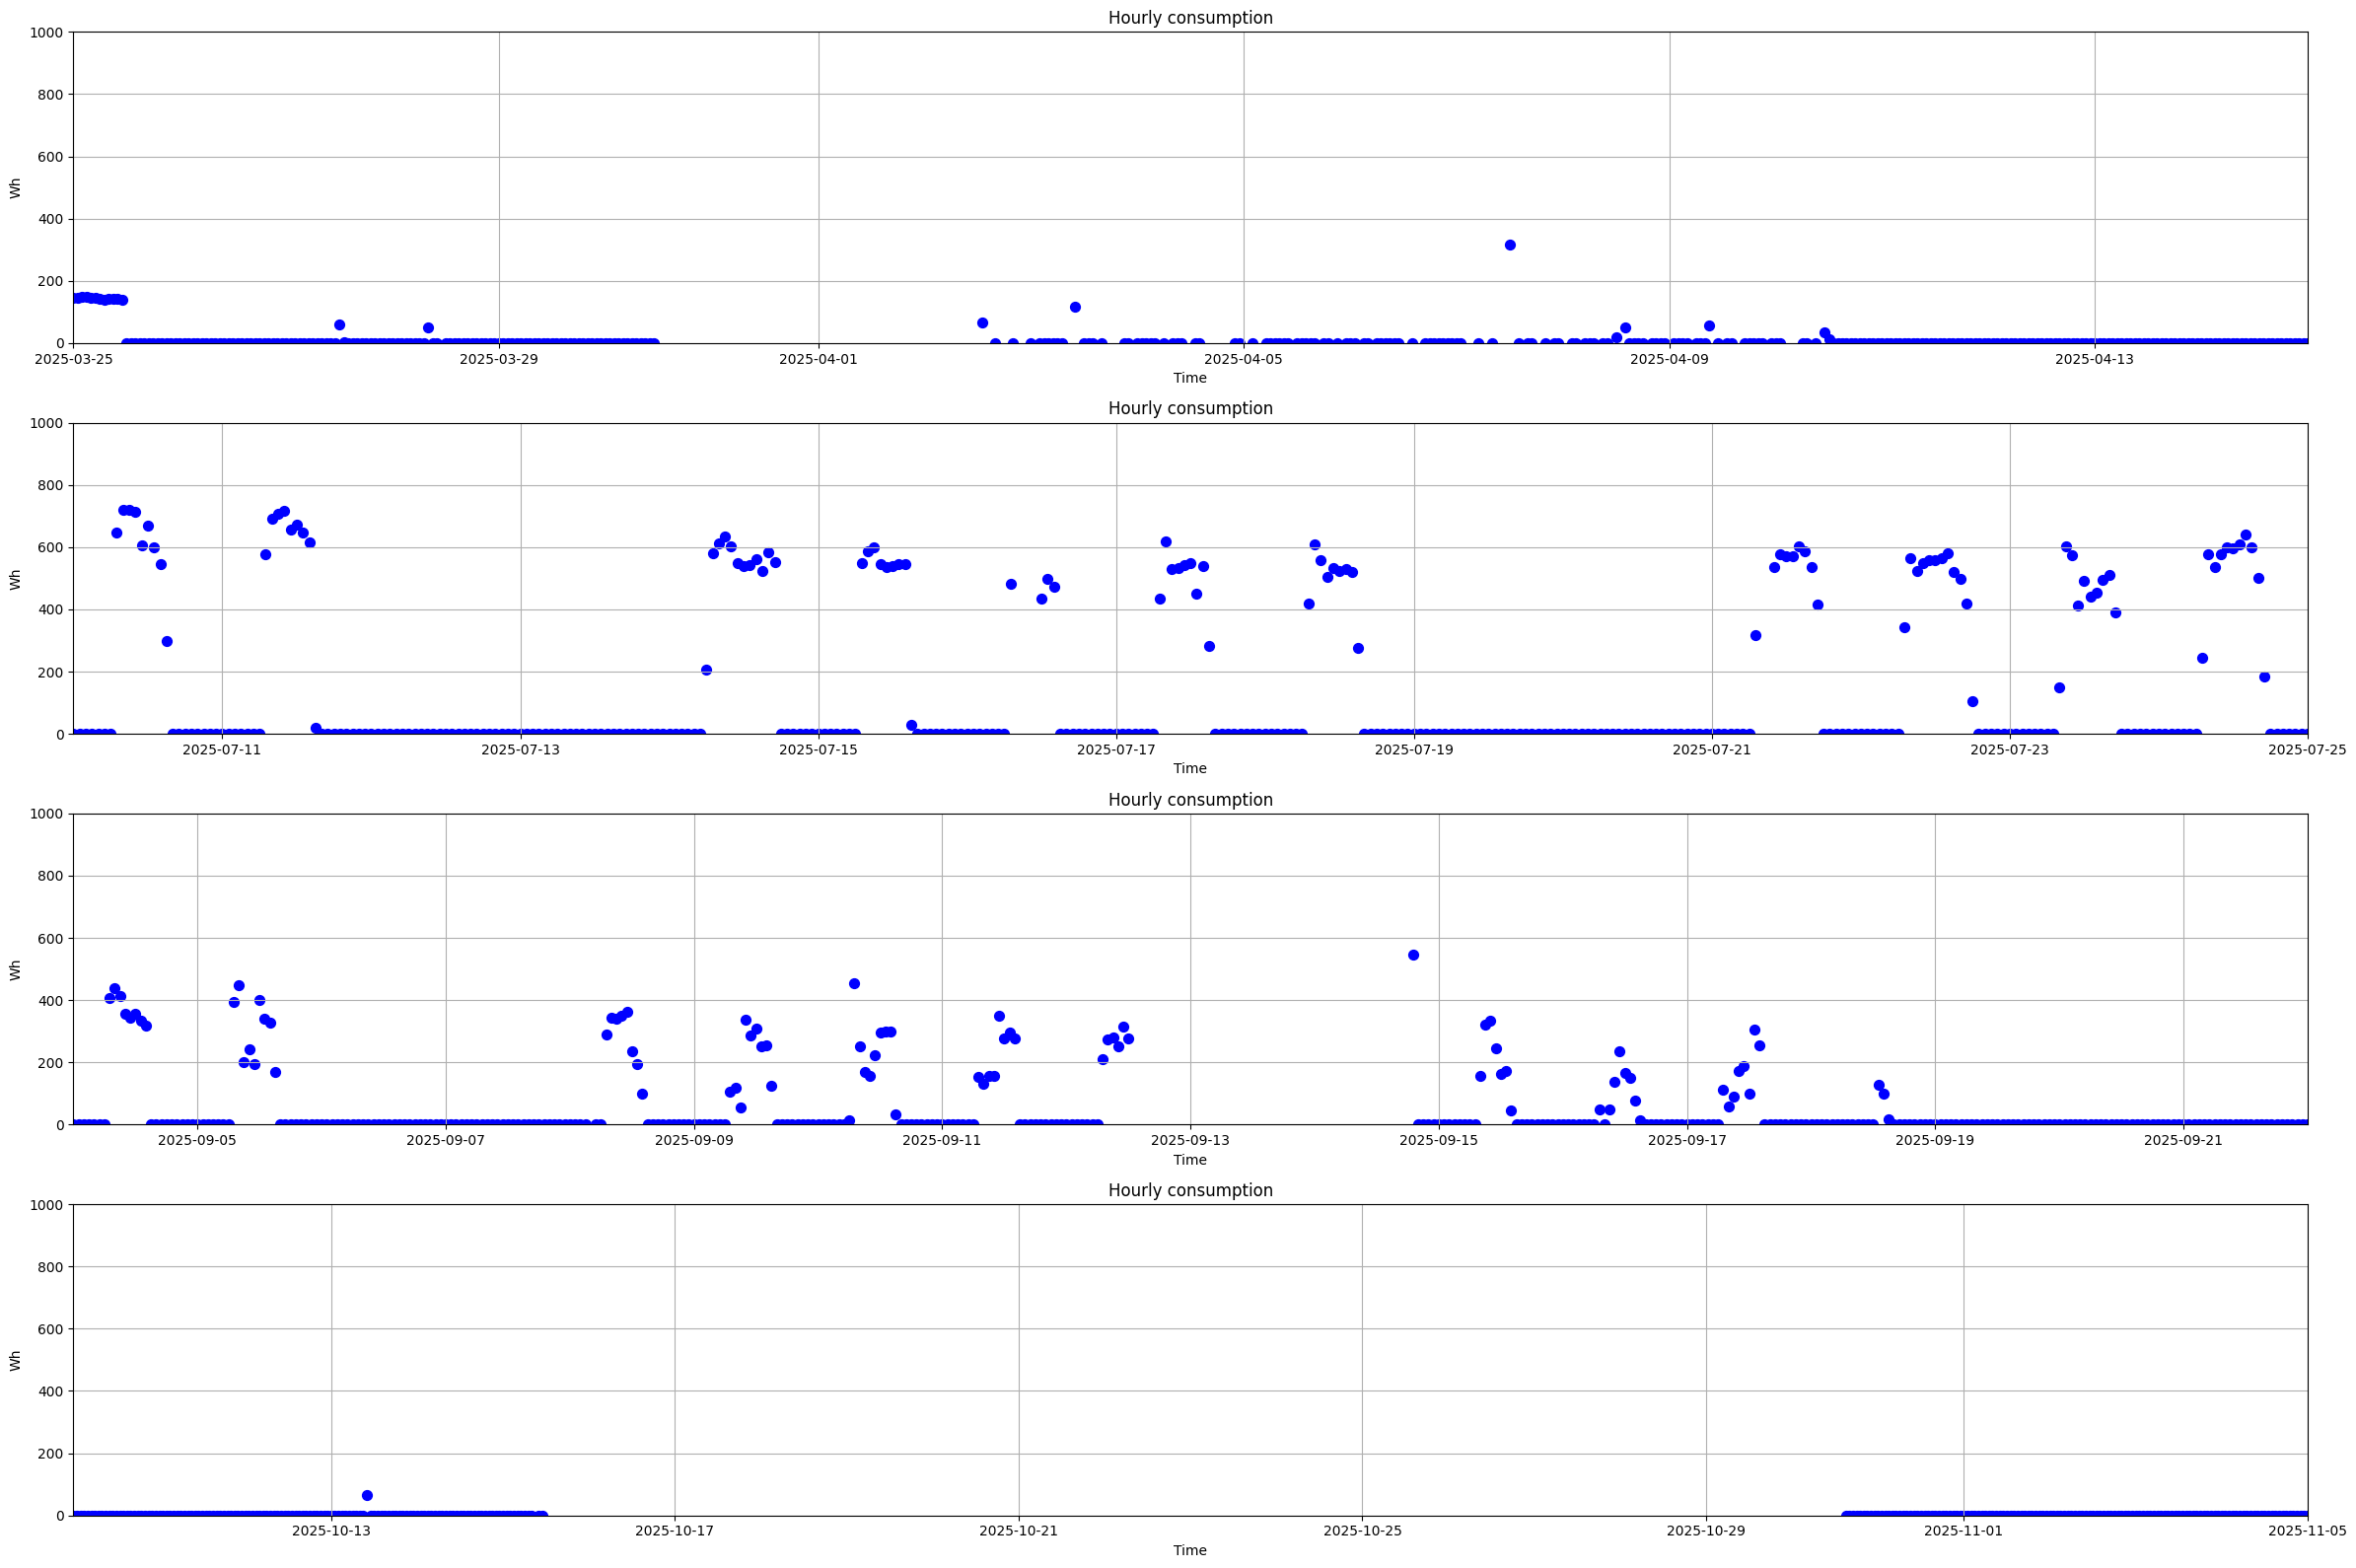

In [11]:
date_ranges = [
    ('2025-03-25', '2025-04-15'),
    ('2025-07-10', '2025-07-25'),
    ('2025-09-04', '2025-09-22'),
    ('2025-10-10', '2025-11-05')
]

fig, axes = plt.subplots(4, 1, figsize=(24, 16))

for ax, (start, end) in zip(axes, date_ranges):
    # ax.plot(df.index, df['consumption_full'], color='black', linewidth=0.5)
    # ax.scatter(df.index, df['consumption_full'], color='red', s=10, alpha=0.7)
    ax.scatter(df.index, df['consumption'], color='blue', s=50, alpha=1)
    
    ax.grid(True)
    ax.set_title("Hourly consumption")
    ax.set_ylim(0, 1000)
    ax.set_xlabel("Time")
    ax.set_ylabel("Wh")
    ax.set_xlim(pd.to_datetime(start), pd.to_datetime(end))

plt.tight_layout()
plt.show()

### Identifying possible anomalies in consumption series

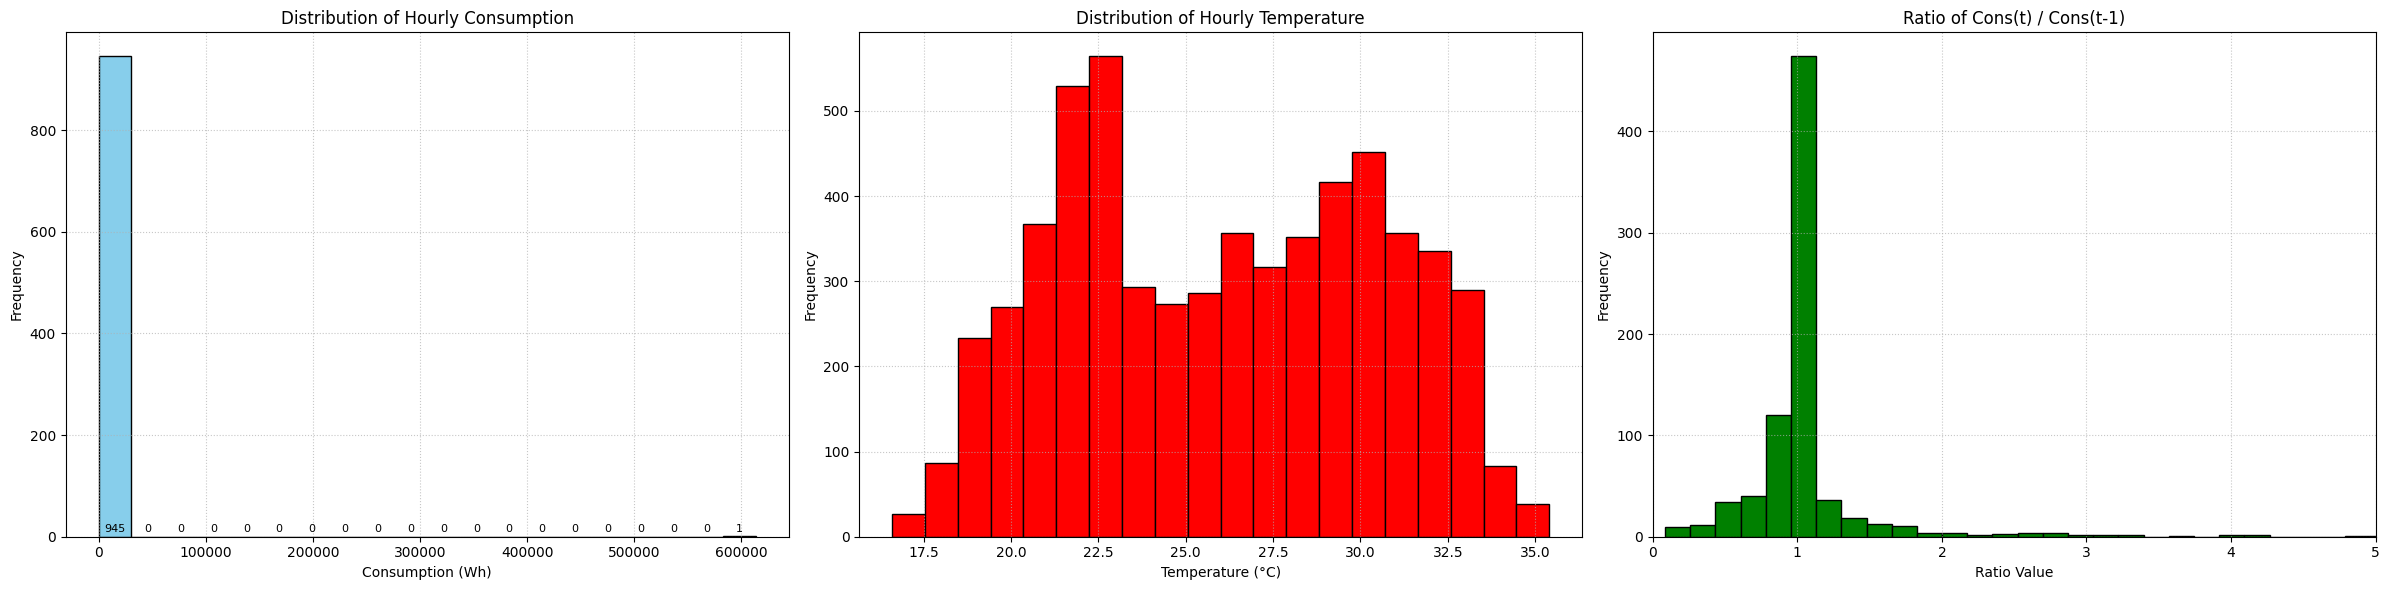

In [12]:
# Logic for the Ratio Calculation
curr_cons = df['consumption']
prev_cons = df['consumption'].shift(1)

mask = (curr_cons > 50) & (prev_cons > 50)
consumption_ratio = np.where(mask, curr_cons / prev_cons, 0) #if mask=1 -> consumption_ratio = curr_cons/prev_cons, else 0
ratios_to_plot = consumption_ratio[consumption_ratio > 0]

# Plotting
plt.figure(figsize=(24, 6))

# Plot 1: Consumption
consumptions_to_plot = df['consumption'][df['consumption'] > 0]
plt.subplot(1, 3, 1)
n, bins, patches = plt.hist(consumptions_to_plot.dropna(), bins=20, color='skyblue', edgecolor='black')
plt.title('Distribution of Hourly Consumption')
plt.xlabel('Consumption (Wh)')
plt.ylabel('Frequency')
plt.grid(True, linestyle=':', alpha=0.7)

for patch in patches:
    height = patch.get_height()
    plt.text(patch.get_x() + patch.get_width() / 2, 5,
             f'{int(height)}', ha='center', va='bottom', fontsize=8, color='black')

# Plot 2: Temperature
plt.subplot(1, 3, 2)
plt.hist(df['temperature'].dropna(), bins=20, color='red', edgecolor='black')
plt.title('Distribution of Hourly Temperature')
plt.xlabel('Temperature (°C)')
plt.ylabel('Frequency')
plt.grid(True, linestyle=':', alpha=0.7)

# Plot 3: Consumption Ratio
plt.subplot(1, 3, 3)
n, bins, patches = plt.hist(ratios_to_plot, bins=50, color='green', edgecolor='black')
plt.title('Ratio of Cons(t) / Cons(t-1)')
plt.xlabel('Ratio Value')
plt.ylabel('Frequency')
plt.grid(True, linestyle=':', alpha=0.7)
plt.xlim(0,5)

plt.tight_layout()
plt.show()

In [13]:
def gap_length_distribution(series, label=None):
    """Table of consecutive-NaN gap lengths (in hours) for a series, printed before it gets filled."""
    is_na = series.isna()
    gap_id = (is_na != is_na.shift()).cumsum()
    gap_lengths = is_na.groupby(gap_id).sum()
    gap_lengths = gap_lengths[gap_lengths > 0].astype(int)

    if label:
        print(f"--- Gap length distribution: {label} ---")
    if gap_lengths.empty:
        print("No gaps found.")
        return pd.DataFrame(columns=['gap_length_hours', 'num_gaps']).set_index('gap_length_hours')

    counts = gap_lengths.value_counts().sort_index()
    print(f"Total gaps: {len(gap_lengths)}, total missing hours: {int(gap_lengths.sum())}")
    for length, count in counts.items():
        hour_word = 'hour' if length == 1 else 'hours'
        print(f"  {count} gap(s) of {length} {hour_word}")

    table = counts.rename('num_gaps').rename_axis('gap_length_hours').to_frame()
    return table

In [14]:
gap_length_distribution(df['consumption'], label='Office 12')

--- Gap length distribution: Office 12 ---
Total gaps: 61, total missing hours: 582
  39 gap(s) of 1 hour
  11 gap(s) of 2 hours
  4 gap(s) of 3 hours
  3 gap(s) of 4 hours
  1 gap(s) of 7 hours
  1 gap(s) of 54 hours
  1 gap(s) of 73 hours
  1 gap(s) of 363 hours


,num_gaps
gap_length_hours,
1,39
2,11
3,4
4,3
7,1
54,1
73,1
363,1


### Outlier nulling + context-pooled gap fill



In [15]:
def gather_week_candidates(ts, raw_series):

    vals = []
    for offset in (-1, 1):
        ref_ts = ts + pd.Timedelta(weeks=offset)
        if ref_ts in raw_series.index:
            val = raw_series.loc[ref_ts]
            if not np.isnan(val):
                vals.append(val)
    return vals


def nearest_working_day(ts, direction):

    step = pd.Timedelta(days=1) * direction
    candidate = ts + step
    while candidate.weekday() >= 5:
        candidate += step
    return candidate


def estimate_reference(ts, raw_series):

    candidates = list(gather_week_candidates(ts, raw_series))

    for direction in (-1, 1):
        day_ts = nearest_working_day(ts, direction)
        if day_ts in raw_series.index:
            val = raw_series.loc[day_ts]
            if not np.isnan(val):
                candidates.append(val)

    for delta_h in (-1, 1):
        hour_ts = ts + pd.Timedelta(hours=delta_h)
        if hour_ts in raw_series.index:
            val = raw_series.loc[hour_ts]
            if not np.isnan(val):
                candidates.append(val)

    if not candidates:
        return np.nan
    return float(np.mean(candidates))

In [16]:
def null_outliers(df_in, raw_col, ceiling, label):

    raw = df_in[raw_col].to_numpy(dtype=float).copy()
    idx = df_in.index
    n = len(raw)

    def preceding_nan_streak(pos):
        k = 0
        p = pos - 1
        while p >= 0 and np.isnan(raw[p]):
            k += 1
            p -= 1
        return k

    above_ceiling = (~np.isnan(raw)) & (raw > ceiling)

    lone_spike = np.zeros(n, dtype=bool)
    streak_len = np.zeros(n, dtype=int)
    for pos in np.where((~np.isnan(raw)) & (raw > 200))[0]:
        k = preceding_nan_streak(pos)
        streak_len[pos] = k
        if k > 1:
            lone_spike[pos] = True

    flagged_mask = above_ceiling | lone_spike

    reasons = []
    for pos in np.where(flagged_mask)[0]:
        parts = []
        if above_ceiling[pos]:
            parts.append(f"above ceiling ({ceiling} Wh)")
        if lone_spike[pos]:
            parts.append(f"lone spike after {streak_len[pos]} NaNs")
        reasons.append(" & ".join(parts))

    flagged_log = pd.DataFrame({
        'timestamp': idx[flagged_mask],
        'value': raw[flagged_mask],
        'reason': reasons,
    })

    out = raw.copy()
    out[flagged_mask] = np.nan

    print(f"--- Outlier nulling: {label} (ceiling={ceiling} Wh) ---")
    print(f"Flagged and nulled: {flagged_mask.sum()} "
          f"(above ceiling: {above_ceiling.sum()}, lone spike after gap: {lone_spike.sum()}, "
          f"both: {(above_ceiling & lone_spike).sum()})")

    result = df_in.copy()
    result[raw_col + '_handled'] = out
    return result, flagged_log

In [17]:
PLAUSIBILITY_CEILING = 800  # Office 12 (Wh)

df, flagged_log = null_outliers(df, 'consumption', PLAUSIBILITY_CEILING, 'Office 12')

print("\nFlagged as outliers (nulled):")
display(flagged_log.round(2) if not flagged_log.empty else flagged_log)

--- Outlier nulling: Office 12 (ceiling=800 Wh) ---
Flagged and nulled: 7 (above ceiling: 4, lone spike after gap: 3, both: 0)

Flagged as outliers (nulled):


C:\Users\yiann\AppData\Local\Temp\ipykernel_22704\1409530828.py:6: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(flagged_log.round(2) if not flagged_log.empty else flagged_log)


,timestamp,value,reason
0,2025-03-28 11:00:00,613242.10,above ceiling (800 Wh)
1,2025-04-07 12:00:00,315.72,lone spike after 3 NaNs
2,2025-06-17 14:00:00,1064.75,above ceiling (800 Wh)
3,2025-07-16 12:00:00,433.25,lone spike after 4 NaNs
4,2025-07-21 09:00:00,1039.53,above ceiling (800 Wh)
5,2025-07-28 14:00:00,1108.63,above ceiling (800 Wh)
6,2025-09-14 19:00:00,547.37,lone spike after 54 NaNs


### Fill remaining missing values

In [18]:
# Non-working hours -> 0 
years = df.index.year.unique()
gr_holidays = holidays.Greece(years=years)
is_holiday = pd.Series(df.index.date, index=df.index).isin(gr_holidays).to_numpy()

is_weekend = df.index.dayofweek >= 5
is_off_hours = (df.index.hour < 7) | (df.index.hour >= 19)
off_hours_mask = is_weekend | is_off_hours | is_holiday

consumption_full = df['consumption_handled'].copy()
n_holiday_zeroed = int((is_holiday & consumption_full.isna()).sum())
consumption_full[off_hours_mask & consumption_full.isna()] = 0

# Any remaining NaNs
still_missing = consumption_full[consumption_full.isna()].index
filled_by_reference, filled_by_interpolation = 0, 0

for ts in still_missing:
    ref_val = estimate_reference(ts, df['consumption_handled'])
    if not np.isnan(ref_val):
        consumption_full.loc[ts] = ref_val
        filled_by_reference += 1

# Absolute last resort for any hour with no reference at all
if consumption_full.isna().any():
    before = consumption_full.isna().sum()
    consumption_full = consumption_full.interpolate(method='time')
    filled_by_interpolation = before - consumption_full.isna().sum()

df['consumption_full'] = consumption_full

print(f"Zeroed on Greek public holidays (still-missing hours): {n_holiday_zeroed}")
print(f"Filled via pooled context average: {filled_by_reference}")
print(f"Filled via time interpolation (no reference available): {filled_by_interpolation}")
print(f"Remaining NaNs: {consumption_full.isna().sum()}")

Zeroed on Greek public holidays (still-missing hours): 24
Filled via pooled context average: 195
Filled via time interpolation (no reference available): 16
Remaining NaNs: 0


### Visualizing the raw vs. filled series

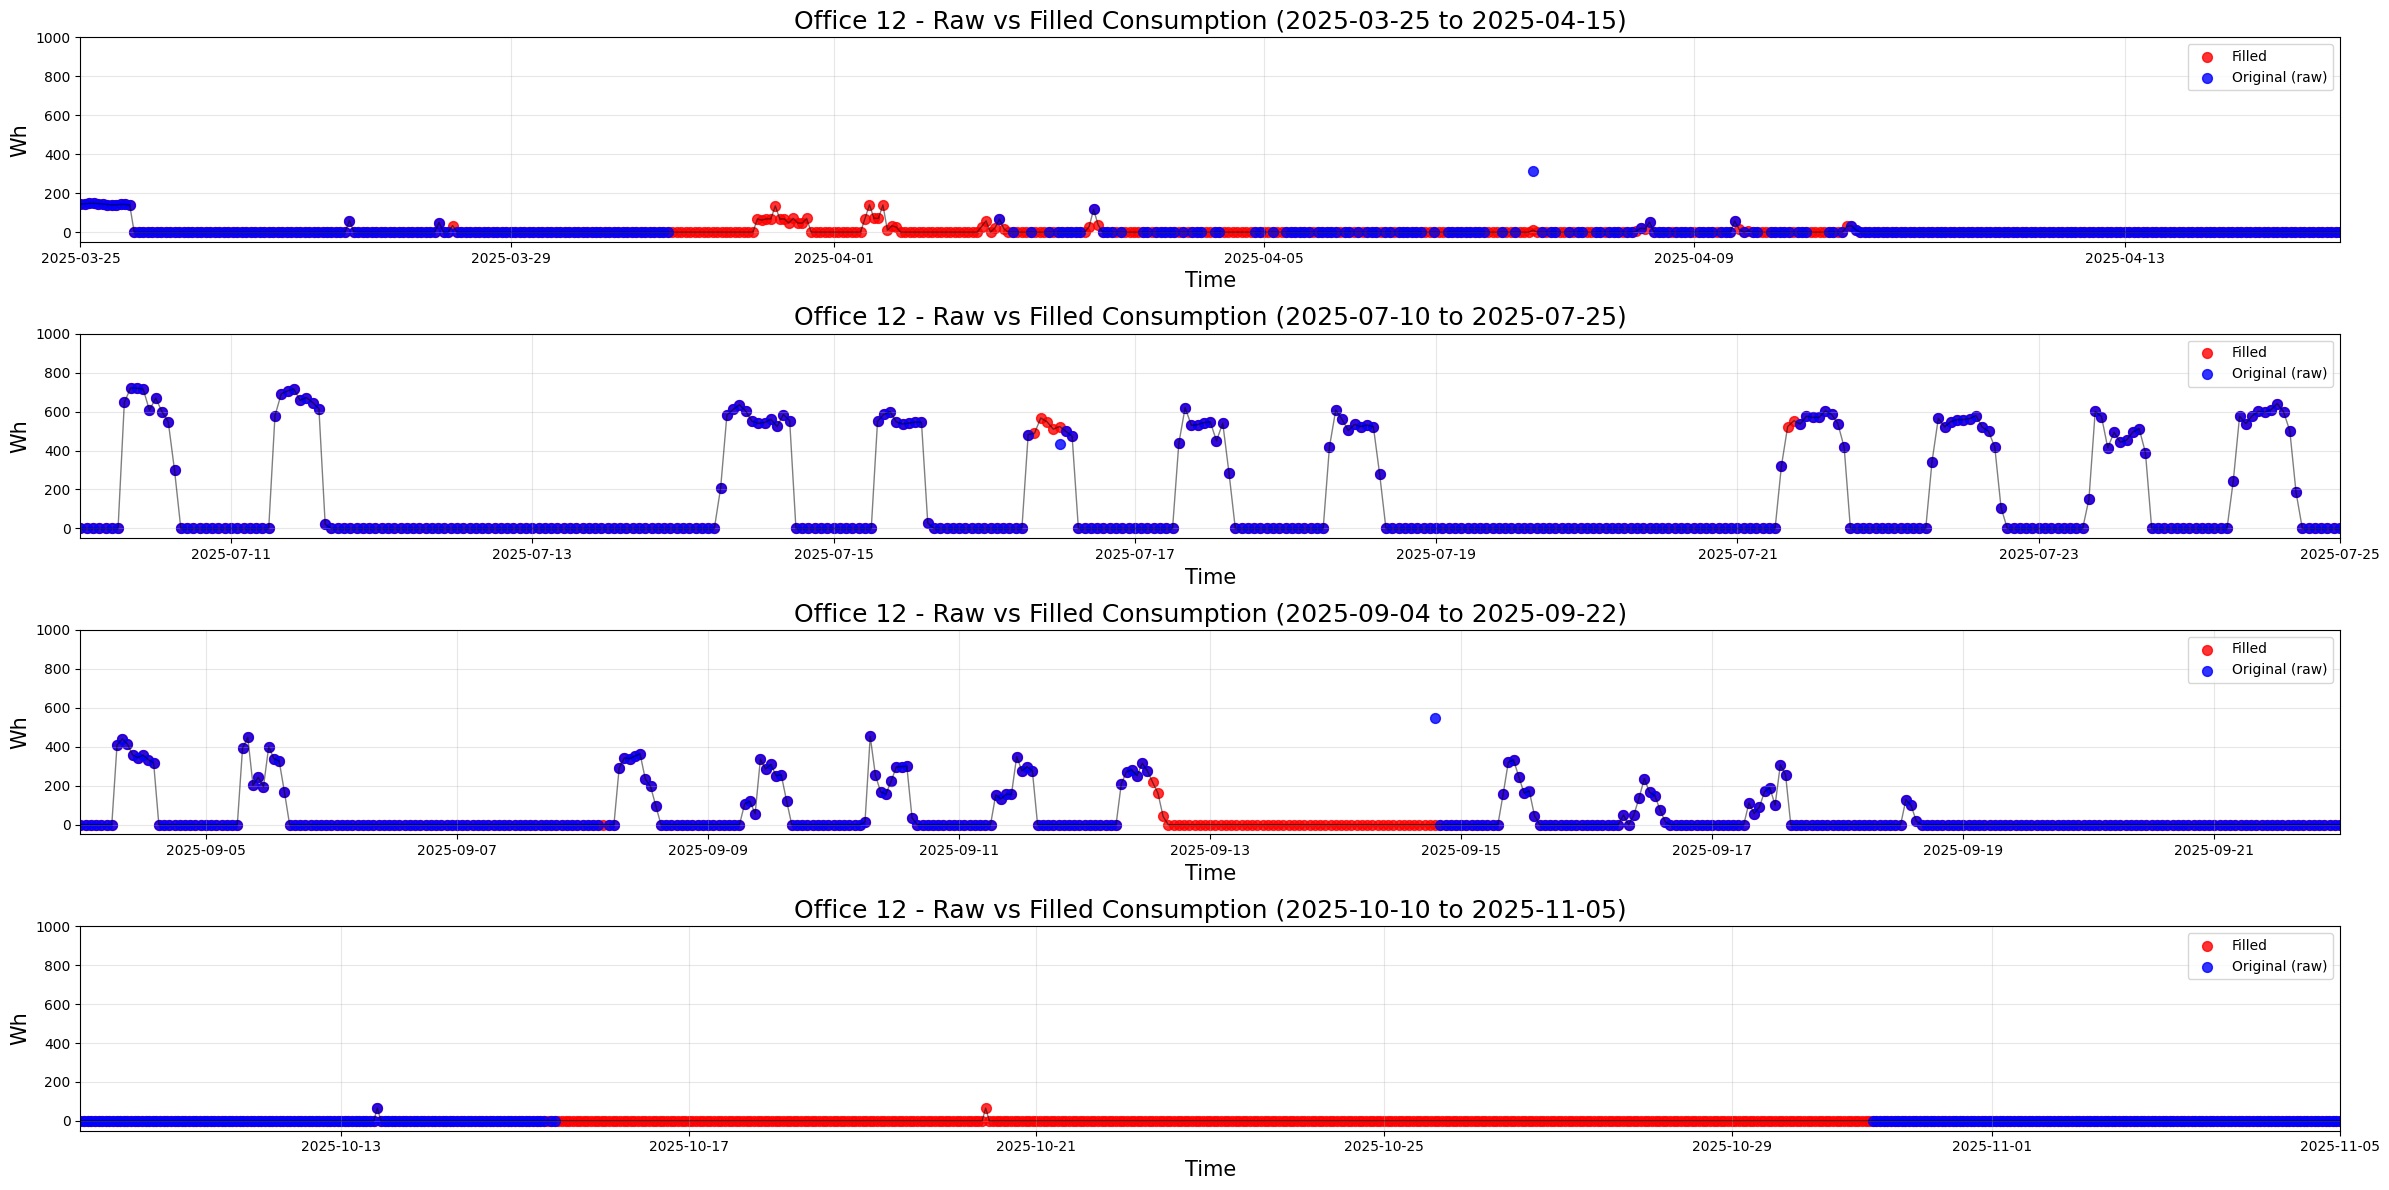

In [19]:
fig, axes = plt.subplots(len(date_ranges), 1, figsize=(24, 3 * len(date_ranges)))

for ax, (start, end) in zip(axes, date_ranges):
    ax.plot(df.index, df['consumption_full'], color='black', linewidth=1, alpha=0.5)
    ax.scatter(df.index, df['consumption_full'], color='red', s=50, alpha=0.8, label='Filled')
    ax.scatter(df.index, df['consumption'], color='blue', s=50, alpha=0.8, label='Original (raw)')
    ax.set_xlim(pd.to_datetime(start), pd.to_datetime(end))
    ax.set_ylim(-50, 1000)
    ax.set_title(f"Office 12 - Raw vs Filled Consumption ({start} to {end})", fontsize=18)
    ax.set_ylabel("Wh", fontsize=15)
    ax.set_xlabel('Time', fontsize=15)
    ax.grid(True, alpha=0.3)
    ax.legend()

axes[-1].set_xlabel("Time")
plt.tight_layout()
plt.show()

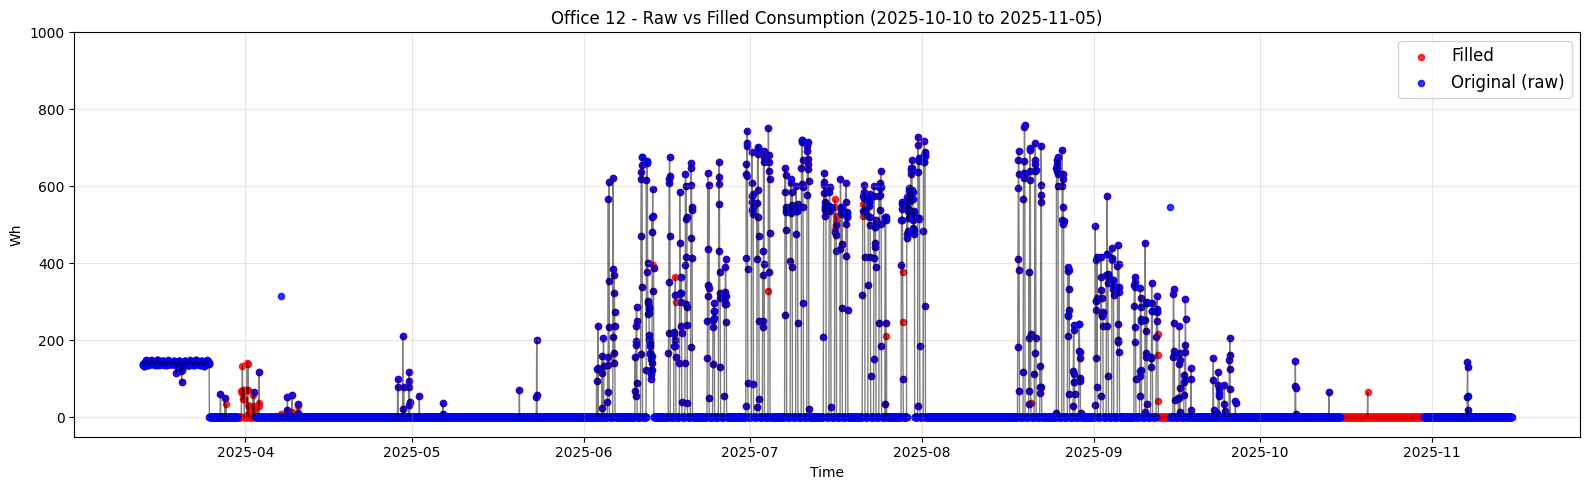

In [20]:
fig = plt.figure(figsize=(16, 5))

plt.plot(df.index, df['consumption_full'], color='black', linewidth=1, alpha=0.5)
plt.scatter(df.index, df['consumption_full'], color='red', s=20, alpha=0.8, label='Filled')
plt.scatter(df.index, df['consumption'], color='blue', s=20, alpha=0.8, label='Original (raw)')
plt.ylim(-50, 1000)
plt.title(f"Office 12 - Raw vs Filled Consumption ({start} to {end})")
plt.ylabel("Wh")
plt.grid(True, alpha=0.3)
plt.legend(fontsize=12)

plt.xlabel("Time")
plt.tight_layout()
plt.show()

### Save

In [21]:
#df.to_excel("../data/consumption12_filled.xlsx")
print("Saved consumption12_filled.xlsx")

Saved consumption12_filled.xlsx


# Office 35 (sensor 1249)

### Pre-processing

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import datetime
import holidays

file_path = "../data/office_temps_combined_and_aligned.csv"

try:
  temperatures = pd.read_csv(file_path)

except FileNotFoundError:
  print(f"File not found: {file_path}")
except Exception as e:
  print(f"An error occurred while loading the file: {e}")

In [23]:
temperatures = temperatures.rename(columns={'Unnamed: 0': 'timestamp'})
temperatures['timestamp'] = pd.to_datetime(temperatures['timestamp'])
temperatures = temperatures.set_index('timestamp')
temperatures = temperatures[['o35_full']]
temperatures = temperatures.dropna()
print(temperatures.head())
print(temperatures.tail())
print(temperatures.shape)

                     o35_full
timestamp                    
2024-11-27 11:00:00      22.7
2024-11-27 12:00:00      23.2
2024-11-27 13:00:00      23.5
2024-11-27 14:00:00      23.7
2024-11-27 15:00:00      23.6
                     o35_full
timestamp                    
2025-11-21 13:00:00      23.0
2025-11-21 14:00:00      23.2
2025-11-21 15:00:00      23.4
2025-11-21 16:00:00      23.2
2025-11-21 17:00:00      23.0
(8623, 1)


In [24]:
file_path = "../data/consumption35.xlsx"

try:
  df = pd.read_excel(file_path)
  print(df.head(-3))

except FileNotFoundError:
  print(f"File not found: {file_path}")
except Exception as e:
  print(f"An error occurred while loading the file: {e}")

               timestamp  consumption  Στήλη 1  Στήλη 2  Στήλη 3  Στήλη 4
0    2024-11-04 01:00:00          NaN      NaN      NaN      NaN      NaN
1    2024-11-04 02:00:00         0.00      NaN      NaN      NaN      NaN
2    2024-11-04 03:00:00         0.00      NaN      NaN      NaN      NaN
3    2024-11-04 04:00:00         0.00      NaN      NaN      NaN      NaN
4    2024-11-04 05:00:00         0.00      NaN      NaN      NaN      NaN
...                  ...          ...      ...      ...      ...      ...
8240 2025-11-15 02:00:00       102.13      NaN      NaN      NaN      NaN
8241 2025-11-15 03:00:00       102.06      NaN      NaN      NaN      NaN
8242 2025-11-15 04:00:00       101.96      NaN      NaN      NaN      NaN
8243 2025-11-15 05:00:00       101.73      NaN      NaN      NaN      NaN
8244 2025-11-15 06:00:00       100.63      NaN      NaN      NaN      NaN

[8245 rows x 6 columns]


In [25]:
df = df[['timestamp', 'consumption']]
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.drop(0)
print(df.dtypes)
print("There are ",len(df), " entries")
df

timestamp      datetime64[us]
consumption           float64
dtype: object
There are  8247  entries


,timestamp,consumption
1,2024-11-04 02:00:00,0.00
2,2024-11-04 03:00:00,0.00
3,2024-11-04 04:00:00,0.00
4,2024-11-04 05:00:00,0.00
5,2024-11-04 06:00:00,0.00
...,...,...
8243,2025-11-15 05:00:00,101.73
8244,2025-11-15 06:00:00,100.63
8245,2025-11-15 07:00:00,98.51
8246,2025-11-15 08:00:00,96.84


In [26]:
duplicate_timestamps = df[df.index.duplicated(keep=False)].index.unique()

if not duplicate_timestamps.empty:
    print(f"Duplicate timestamps found: {duplicate_timestamps.tolist()}")
    df = df.groupby(df.index).mean(numeric_only=True) # Merge by averaging consumption
    print("Duplicate timestamps have been merged by averaging their consumption values.")
else:
    print("No duplicate timestamps found.")

print("Current DataFrame shape after checking for duplicates:", df.shape)

No duplicate timestamps found.
Current DataFrame shape after checking for duplicates: (8247, 2)


### Ορισμός του timestamp ως index. Ορισμός της συχνότητας σε επίπεδο ώρας και εντοπισμός των outliers

In [27]:
import holidays

df = df.set_index('timestamp')
df = df.resample('h').mean()
missing = df[df['consumption'].isna()]
df['day_name'] = df.index.day_name()
df['month'] = df.index.month_name()

years = df.index.year.unique()
gr_holidays = holidays.Greece(years=years)

missing_on_holidays = missing[
    pd.Series(missing.index.date, index=missing.index).isin(gr_holidays)
]
num_missing_holidays = len(missing_on_holidays)

print(f"There are {len(df)} entries, including {len(missing)} who are NaN")
print(
    f"Out of the missing entries, {num_missing_holidays} fall on a Greek public holiday."
)

There are 9032 entries, including 785 who are NaN
Out of the missing entries, 48 fall on a Greek public holiday.


In [28]:
def missing_value_summary(df, columns):
    rows = []
    for col in columns:
        series = df[col]
        valid = series.dropna()

        if valid.empty:
            rows.append({'column': col, 'start': None, 'end': None, 'length': 0, 'missing': 0, 'missing_pct': 0.0})
            continue

        start = valid.index.min()
        end = valid.index.max()
        window = series.loc[start:end]
        length = len(window)
        missing = int(window.isna().sum())
        missing_pct = round((missing / length) * 100, 2) if length > 0 else 0.0

        rows.append({'column': col, 'start': start, 'end': end, 'length': length, 'missing': missing, 'missing_pct': missing_pct})

    return pd.DataFrame(rows).set_index('column')

consumption_summary = missing_value_summary(df, ['consumption'])
consumption_summary

,start,end,length,missing,missing_pct
column,,,,,
consumption,2024-11-04 02:00:00,2025-11-15 09:00:00,9032,785,8.69


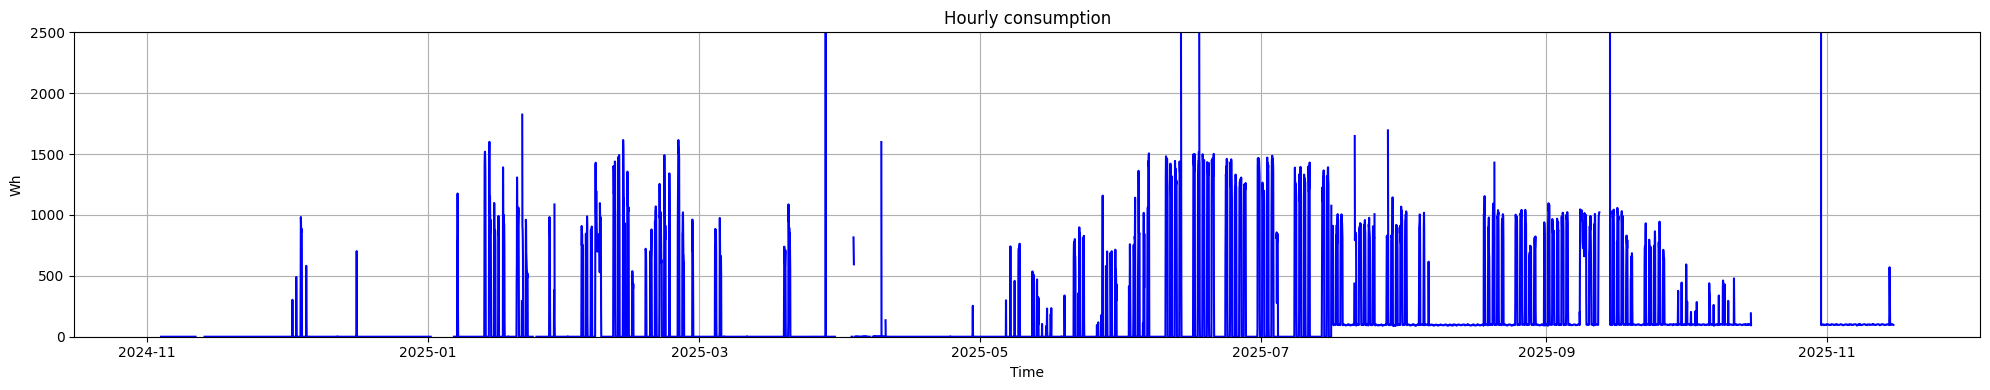

In [29]:
plt.figure(figsize=(20, 4))

plt.plot(df.index, df['consumption'], color='blue')
plt.title("Hourly consumption")
plt.xlabel("Time")
plt.ylabel("Wh")
plt.grid(True)
#plt.xlim(pd.to_datetime('2025-06-01 00:00:00'), pd.to_datetime('2025-08-01 00:00:00'))
plt.ylim(0, 2500)

plt.tight_layout()
plt.show()

### Alignment with indoor temperature

In [30]:
#Add a column for temperature
df_merged = df.join(temperatures, how='left')

later_start_date = max(df.index.min(), temperatures.index.min())
df = df_merged[df_merged.index >= later_start_date]
df = df.rename(columns={'o35_full': 'temperature'})

print(f"Original df start date: {df_merged.index.min()}")
print(f"Temperatures start date: {temperatures.index.min()}")
print(f"New df start date: {df.index.min()}")
print("Merged DataFrame head:")
print(df.head())
print(df.tail())
print(df.shape)

Original df start date: 2024-11-04 02:00:00
Temperatures start date: 2024-11-27 11:00:00
New df start date: 2024-11-27 11:00:00
Merged DataFrame head:
                     consumption   day_name     month  temperature
timestamp                                                         
2024-11-27 11:00:00         0.00  Wednesday  November         22.7
2024-11-27 12:00:00         0.01  Wednesday  November         23.2
2024-11-27 13:00:00         0.00  Wednesday  November         23.5
2024-11-27 14:00:00         0.00  Wednesday  November         23.7
2024-11-27 15:00:00         0.00  Wednesday  November         23.6
                     consumption  day_name     month  temperature
timestamp                                                        
2025-11-15 05:00:00       101.73  Saturday  November         19.5
2025-11-15 06:00:00       100.63  Saturday  November         19.5
2025-11-15 07:00:00        98.51  Saturday  November         19.7
2025-11-15 08:00:00        96.84  Saturday  Novemb

In [31]:
df

,consumption,day_name,month,temperature
timestamp,,,,
2024-11-27 11:00:00,0.00,Wednesday,November,22.7
2024-11-27 12:00:00,0.01,Wednesday,November,23.2
2024-11-27 13:00:00,0.00,Wednesday,November,23.5
2024-11-27 14:00:00,0.00,Wednesday,November,23.7
2024-11-27 15:00:00,0.00,Wednesday,November,23.6
...,...,...,...,...
2025-11-15 05:00:00,101.73,Saturday,November,19.5
2025-11-15 06:00:00,100.63,Saturday,November,19.5
2025-11-15 07:00:00,98.51,Saturday,November,19.7


### Key intervals with missing values

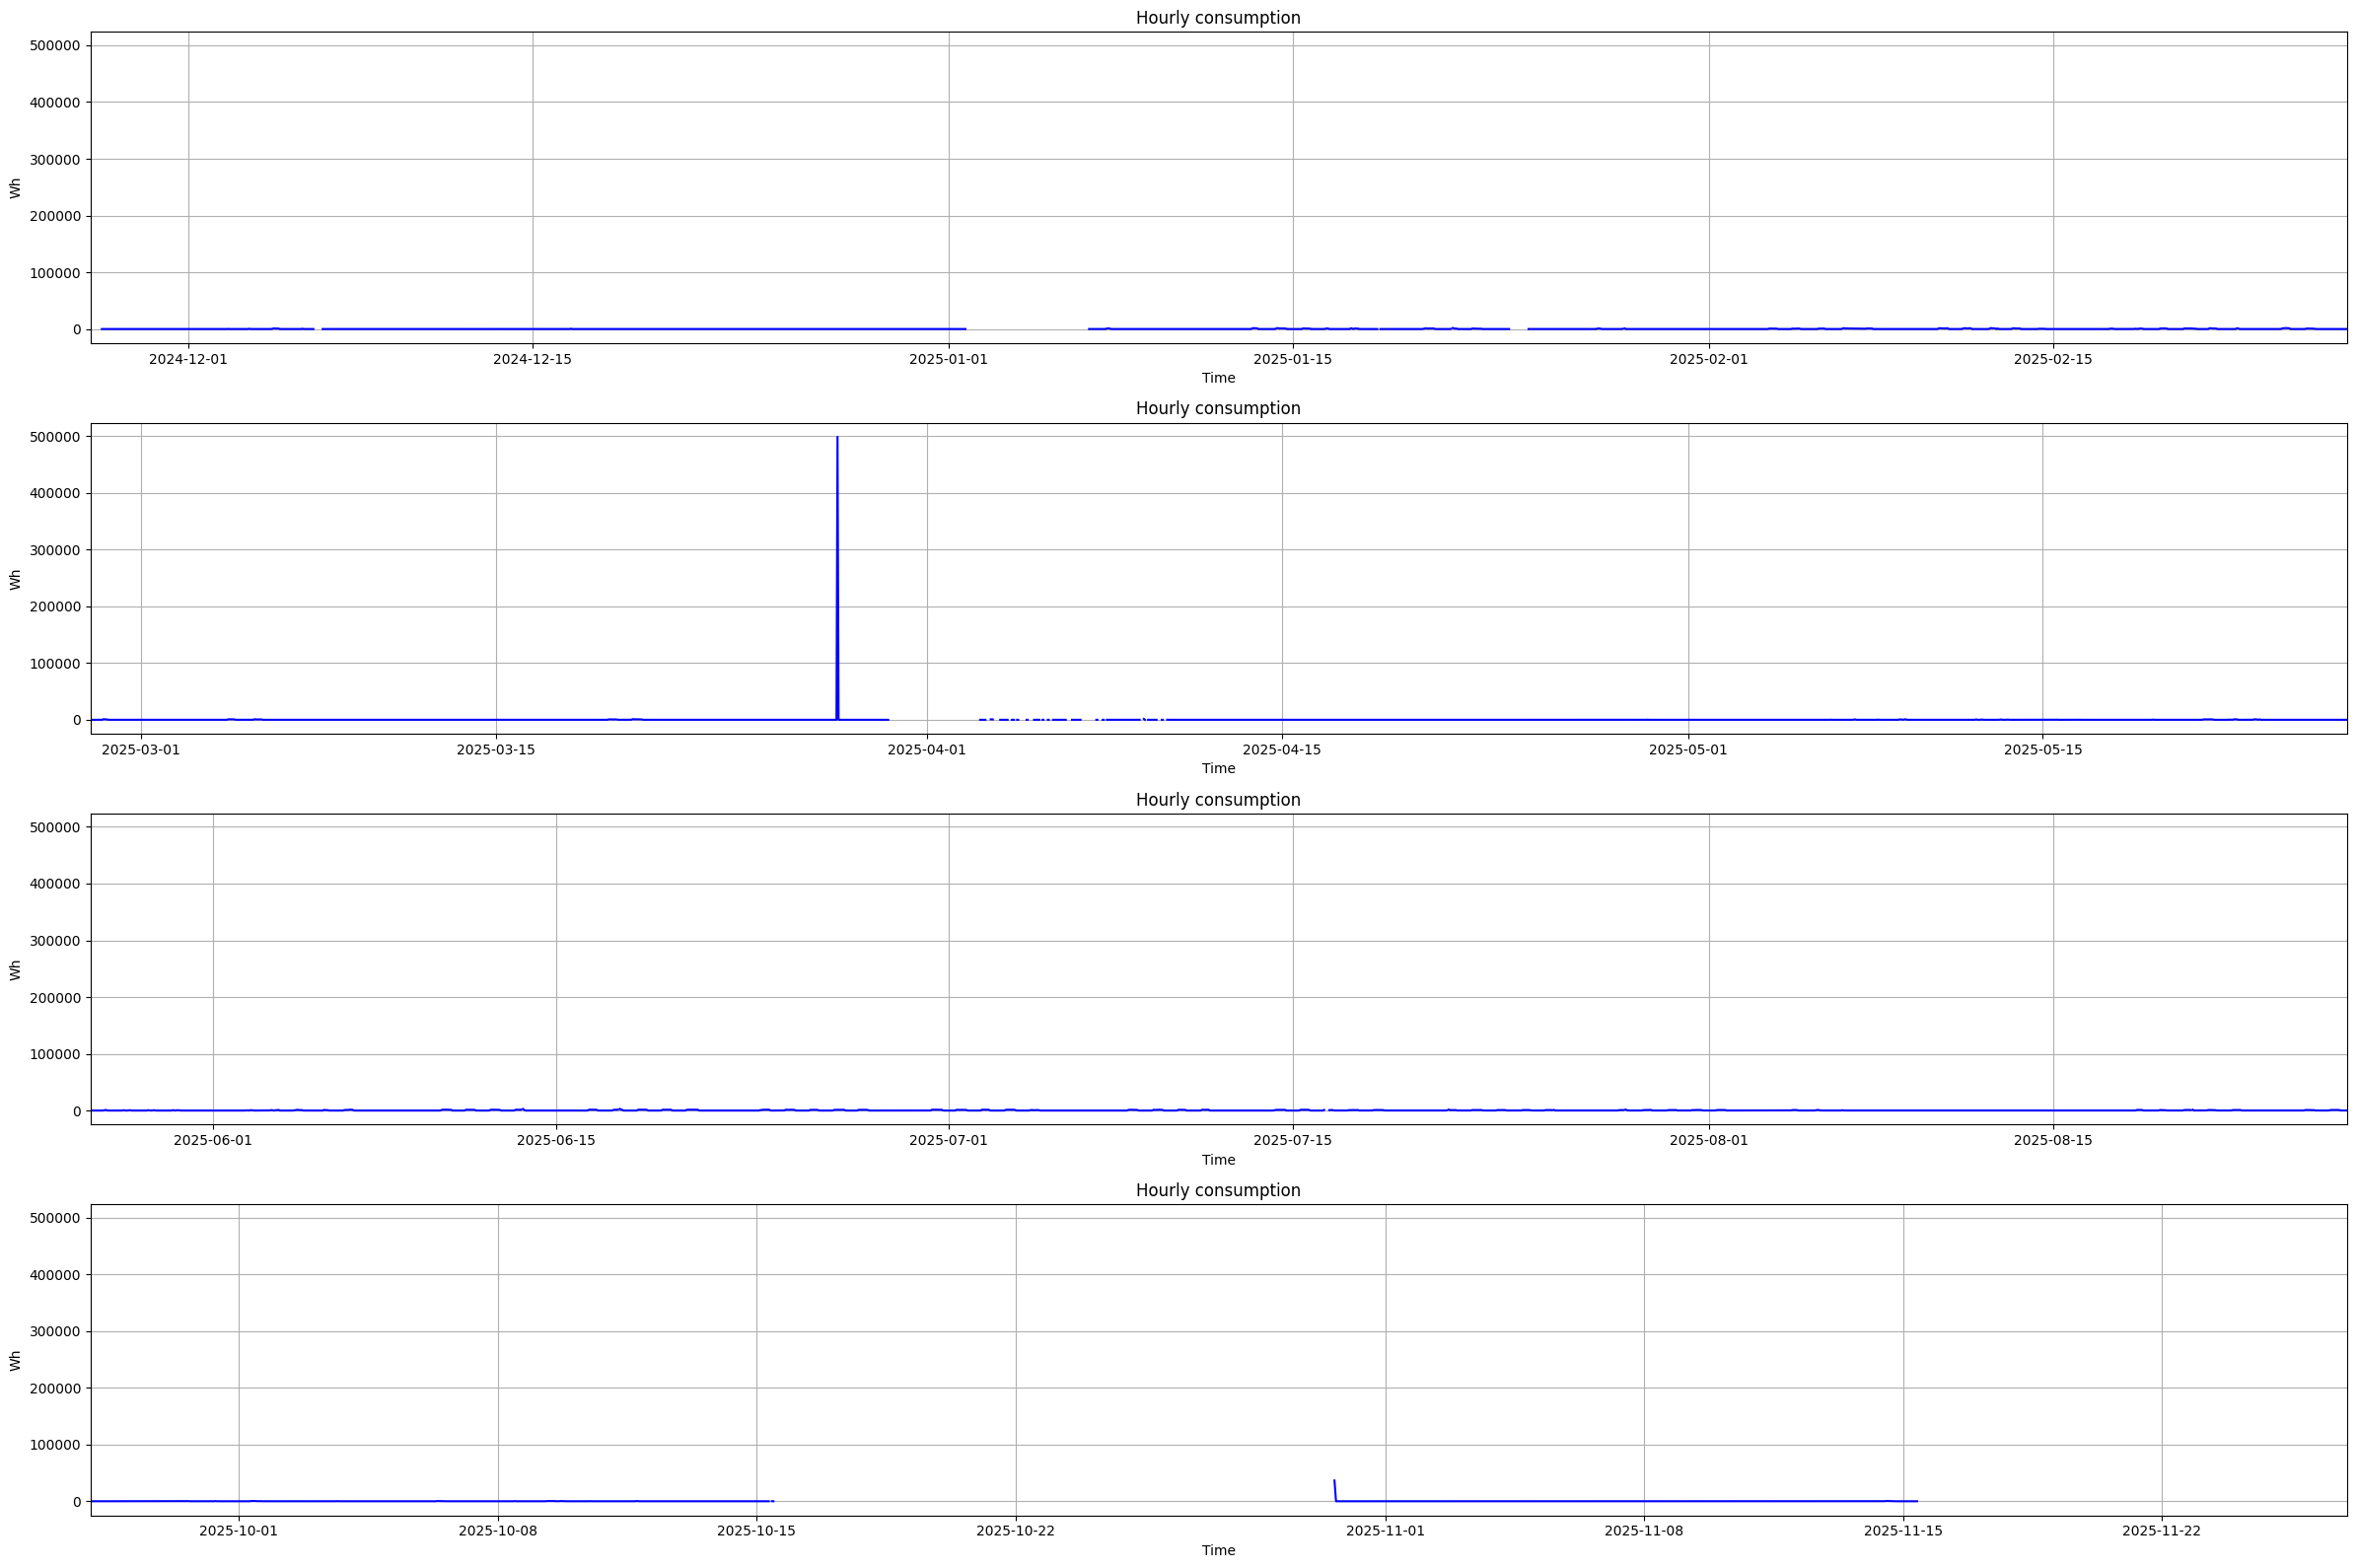

In [32]:
import matplotlib.pyplot as plt
import pandas as pd

date_ranges = [
    ('2024-11-27', '2025-02-27'),
    ('2025-02-27', '2025-05-27'),
    ('2025-05-27', '2025-08-27'),
    ('2025-09-27', '2025-11-27')
]

fig, axes = plt.subplots(4, 1, figsize=(24, 16))

for ax, (start, end) in zip(axes, date_ranges):
    # ax.plot(df.index, df['consumption_full'], color='black', linewidth=0.5)
    # ax.scatter(df.index, df['consumption_full'], color='red', s=5, alpha=0.7)
    
    ax.plot(df.index, df['consumption'], color='blue')
    ax.grid(True)
    ax.set_title("Hourly consumption")
    ax.set_xlabel("Time")
    ax.set_ylabel("Wh")
    ax.set_xlim(pd.to_datetime(start), pd.to_datetime(end))

plt.tight_layout()
plt.show()

### Identifying possible anomalies in consumption series

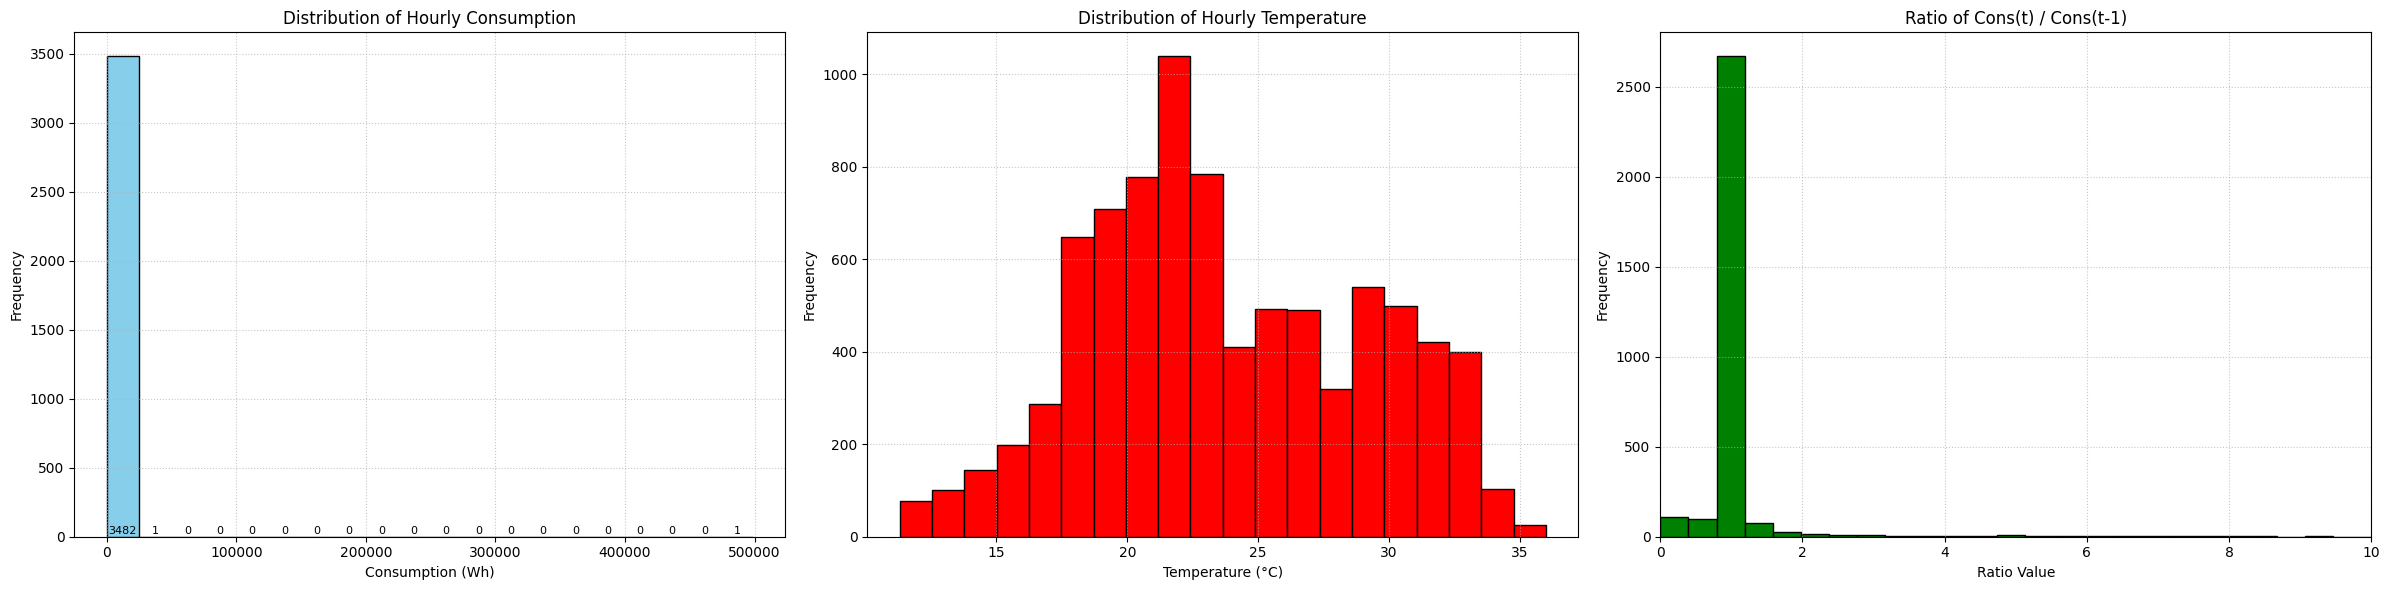

In [33]:
#Logic for the Ratio Calculation
curr_cons = df['consumption']
prev_cons = df['consumption'].shift(1)

mask = (curr_cons > 50) & (prev_cons > 50)
consumption_ratio = np.where(mask, curr_cons / prev_cons, 0)
ratios_to_plot = consumption_ratio[consumption_ratio > 0]

# Plotting
plt.figure(figsize=(24, 6))

# Plot 1: Consumption
consumptions_to_plot = df['consumption'][df['consumption'] > 0]
plt.subplot(1, 3, 1)
n, bins, patches = plt.hist(consumptions_to_plot.dropna(), bins=20, color='skyblue', edgecolor='black')
plt.title('Distribution of Hourly Consumption')
plt.xlabel('Consumption (Wh)')
plt.ylabel('Frequency')
plt.grid(True, linestyle=':', alpha=0.7)

for patch in patches:
    height = patch.get_height()
    plt.text(patch.get_x() + patch.get_width() / 2, 5,
             f'{int(height)}', ha='center', va='bottom', fontsize=8, color='black')

# Plot 2: Temperature
plt.subplot(1, 3, 2)
plt.hist(df['temperature'].dropna(), bins=20, color='red', edgecolor='black')
plt.title('Distribution of Hourly Temperature')
plt.xlabel('Temperature (°C)')
plt.ylabel('Frequency')
plt.grid(True, linestyle=':', alpha=0.7)

# Plot 3: Consumption Ratio
plt.subplot(1, 3, 3)
n, bins, patches = plt.hist(ratios_to_plot, bins=50, color='green', edgecolor='black')
plt.title('Ratio of Cons(t) / Cons(t-1)')
plt.xlabel('Ratio Value')
plt.ylabel('Frequency')
plt.grid(True, linestyle=':', alpha=0.7)
plt.xlim(0,10)

plt.tight_layout()
plt.show()

In [34]:
def gap_length_distribution(series, label=None):
    """Table of consecutive-NaN gap lengths (in hours) for a series, printed before it gets filled."""
    is_na = series.isna()
    gap_id = (is_na != is_na.shift()).cumsum()
    gap_lengths = is_na.groupby(gap_id).sum()
    gap_lengths = gap_lengths[gap_lengths > 0].astype(int)

    if label:
        print(f"--- Gap length distribution: {label} ---")
    if gap_lengths.empty:
        print("No gaps found.")
        return pd.DataFrame(columns=['gap_length_hours', 'num_gaps']).set_index('gap_length_hours')

    counts = gap_lengths.value_counts().sort_index()
    print(f"Total gaps: {len(gap_lengths)}, total missing hours: {int(gap_lengths.sum())}")
    for length, count in counts.items():
        hour_word = 'hour' if length == 1 else 'hours'
        print(f"  {count} gap(s) of {length} {hour_word}")

    table = counts.rename('num_gaps').rename_axis('gap_length_hours').to_frame()
    return table

In [35]:
gap_length_distribution(df['consumption'], label='Office 35')

--- Gap length distribution: Office 35 ---
Total gaps: 69, total missing hours: 739
  42 gap(s) of 1 hour
  12 gap(s) of 2 hours
  4 gap(s) of 3 hours
  3 gap(s) of 4 hours
  1 gap(s) of 6 hours
  1 gap(s) of 7 hours
  1 gap(s) of 8 hours
  1 gap(s) of 18 hours
  1 gap(s) of 54 hours
  1 gap(s) of 73 hours
  1 gap(s) of 120 hours
  1 gap(s) of 363 hours


,num_gaps
gap_length_hours,
1,42
2,12
3,4
4,3
6,1
7,1
8,1
18,1
54,1


### Outlier nulling + context-pooled gap fill

In [36]:
def gather_week_candidates(ts, raw_series):
    vals = []
    for offset in (-1, 1):
        ref_ts = ts + pd.Timedelta(weeks=offset)
        if ref_ts in raw_series.index:
            val = raw_series.loc[ref_ts]
            if not np.isnan(val):
                vals.append(val)
    return vals


def nearest_working_day(ts, direction):
    """The nearest day in `direction` (-1 = backward, +1 = forward) that isn't a weekend, skipping Sat/Sun."""
    step = pd.Timedelta(days=1) * direction
    candidate = ts + step
    while candidate.weekday() >= 5:
        candidate += step
    return candidate


def estimate_reference(ts, raw_series):

    candidates = list(gather_week_candidates(ts, raw_series))

    for direction in (-1, 1):
        day_ts = nearest_working_day(ts, direction)
        if day_ts in raw_series.index:
            val = raw_series.loc[day_ts]
            if not np.isnan(val):
                candidates.append(val)

    for delta_h in (-1, 1):
        hour_ts = ts + pd.Timedelta(hours=delta_h)
        if hour_ts in raw_series.index:
            val = raw_series.loc[hour_ts]
            if not np.isnan(val):
                candidates.append(val)

    if not candidates:
        return np.nan
    return float(np.mean(candidates))

In [37]:
def null_outliers(df_in, raw_col, ceiling, label):

    raw = df_in[raw_col].to_numpy(dtype=float).copy()
    idx = df_in.index
    n = len(raw)

    def preceding_nan_streak(pos):
        k = 0
        p = pos - 1
        while p >= 0 and np.isnan(raw[p]):
            k += 1
            p -= 1
        return k

    above_ceiling = (~np.isnan(raw)) & (raw > ceiling)

    lone_spike = np.zeros(n, dtype=bool)
    streak_len = np.zeros(n, dtype=int)
    for pos in np.where((~np.isnan(raw)) & (raw > 200))[0]:
        k = preceding_nan_streak(pos)
        streak_len[pos] = k
        if k > 1:
            lone_spike[pos] = True

    flagged_mask = above_ceiling | lone_spike

    reasons = []
    for pos in np.where(flagged_mask)[0]:
        parts = []
        if above_ceiling[pos]:
            parts.append(f"above ceiling ({ceiling} Wh)")
        if lone_spike[pos]:
            parts.append(f"lone spike after {streak_len[pos]} NaNs")
        reasons.append(" & ".join(parts))

    flagged_log = pd.DataFrame({
        'timestamp': idx[flagged_mask],
        'value': raw[flagged_mask],
        'reason': reasons,
    })

    out = raw.copy()
    out[flagged_mask] = np.nan

    print(f"--- Outlier nulling: {label} (ceiling={ceiling} Wh) ---")
    print(f"Flagged and nulled: {flagged_mask.sum()} "
          f"(above ceiling: {above_ceiling.sum()}, lone spike after gap: {lone_spike.sum()}, "
          f"both: {(above_ceiling & lone_spike).sum()})")

    result = df_in.copy()
    result[raw_col + '_handled'] = out
    return result, flagged_log

In [38]:
PLAUSIBILITY_CEILING = 2000  # Office 35 (Wh)

df, flagged_log = null_outliers(df, 'consumption', PLAUSIBILITY_CEILING, 'Office 35')

print("\nFlagged as outliers (nulled):")
display(flagged_log.round(2) if not flagged_log.empty else flagged_log)

--- Outlier nulling: Office 35 (ceiling=2000 Wh) ---
Flagged and nulled: 6 (above ceiling: 5, lone spike after gap: 3, both: 2)

Flagged as outliers (nulled):


C:\Users\yiann\AppData\Local\Temp\ipykernel_22704\4131886021.py:6: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(flagged_log.round(2) if not flagged_log.empty else flagged_log)


,timestamp,value,reason
0,2025-03-28 11:00:00,498749.64,above ceiling (2000 Wh)
1,2025-06-13 15:00:00,2710.13,above ceiling (2000 Wh)
2,2025-06-17 14:00:00,2898.03,above ceiling (2000 Wh)
3,2025-07-16 12:00:00,711.96,lone spike after 4 NaNs
4,2025-09-14 19:00:00,8535.42,above ceiling (2000 Wh) & lone spike after 54 ...
5,2025-10-30 15:00:00,36717.85,above ceiling (2000 Wh) & lone spike after 363...


### Fill remaining missing values

In [39]:
# Non-working hours -> 0 
years = df.index.year.unique()
gr_holidays = holidays.Greece(years=years)
is_holiday = pd.Series(df.index.date, index=df.index).isin(gr_holidays).to_numpy()

is_weekend = df.index.dayofweek >= 5
is_off_hours = (df.index.hour < 7) | (df.index.hour >= 19)
off_hours_mask = is_weekend | is_off_hours | is_holiday

consumption_full = df['consumption_handled'].copy()
n_holiday_zeroed = int((is_holiday & consumption_full.isna()).sum())
consumption_full[off_hours_mask & consumption_full.isna()] = 0

# Any remaining NaNs
still_missing = consumption_full[consumption_full.isna()].index
filled_by_reference, filled_by_interpolation = 0, 0

for ts in still_missing:
    ref_val = estimate_reference(ts, df['consumption_handled'])
    if not np.isnan(ref_val):
        consumption_full.loc[ts] = ref_val
        filled_by_reference += 1

# Absolute last resort for any hour with no reference at all
if consumption_full.isna().any():
    before = consumption_full.isna().sum()
    consumption_full = consumption_full.interpolate(method='time')
    filled_by_interpolation = before - consumption_full.isna().sum()

df['consumption_full'] = consumption_full

print(f"Zeroed on Greek public holidays (still-missing hours): {n_holiday_zeroed}")
print(f"Filled via pooled context average: {filled_by_reference}")
print(f"Filled via time interpolation (no reference available): {filled_by_interpolation}")
print(f"Remaining NaNs: {consumption_full.isna().sum()}")

Zeroed on Greek public holidays (still-missing hours): 48
Filled via pooled context average: 235
Filled via time interpolation (no reference available): 17
Remaining NaNs: 0


### Visualizing the raw vs. filled series

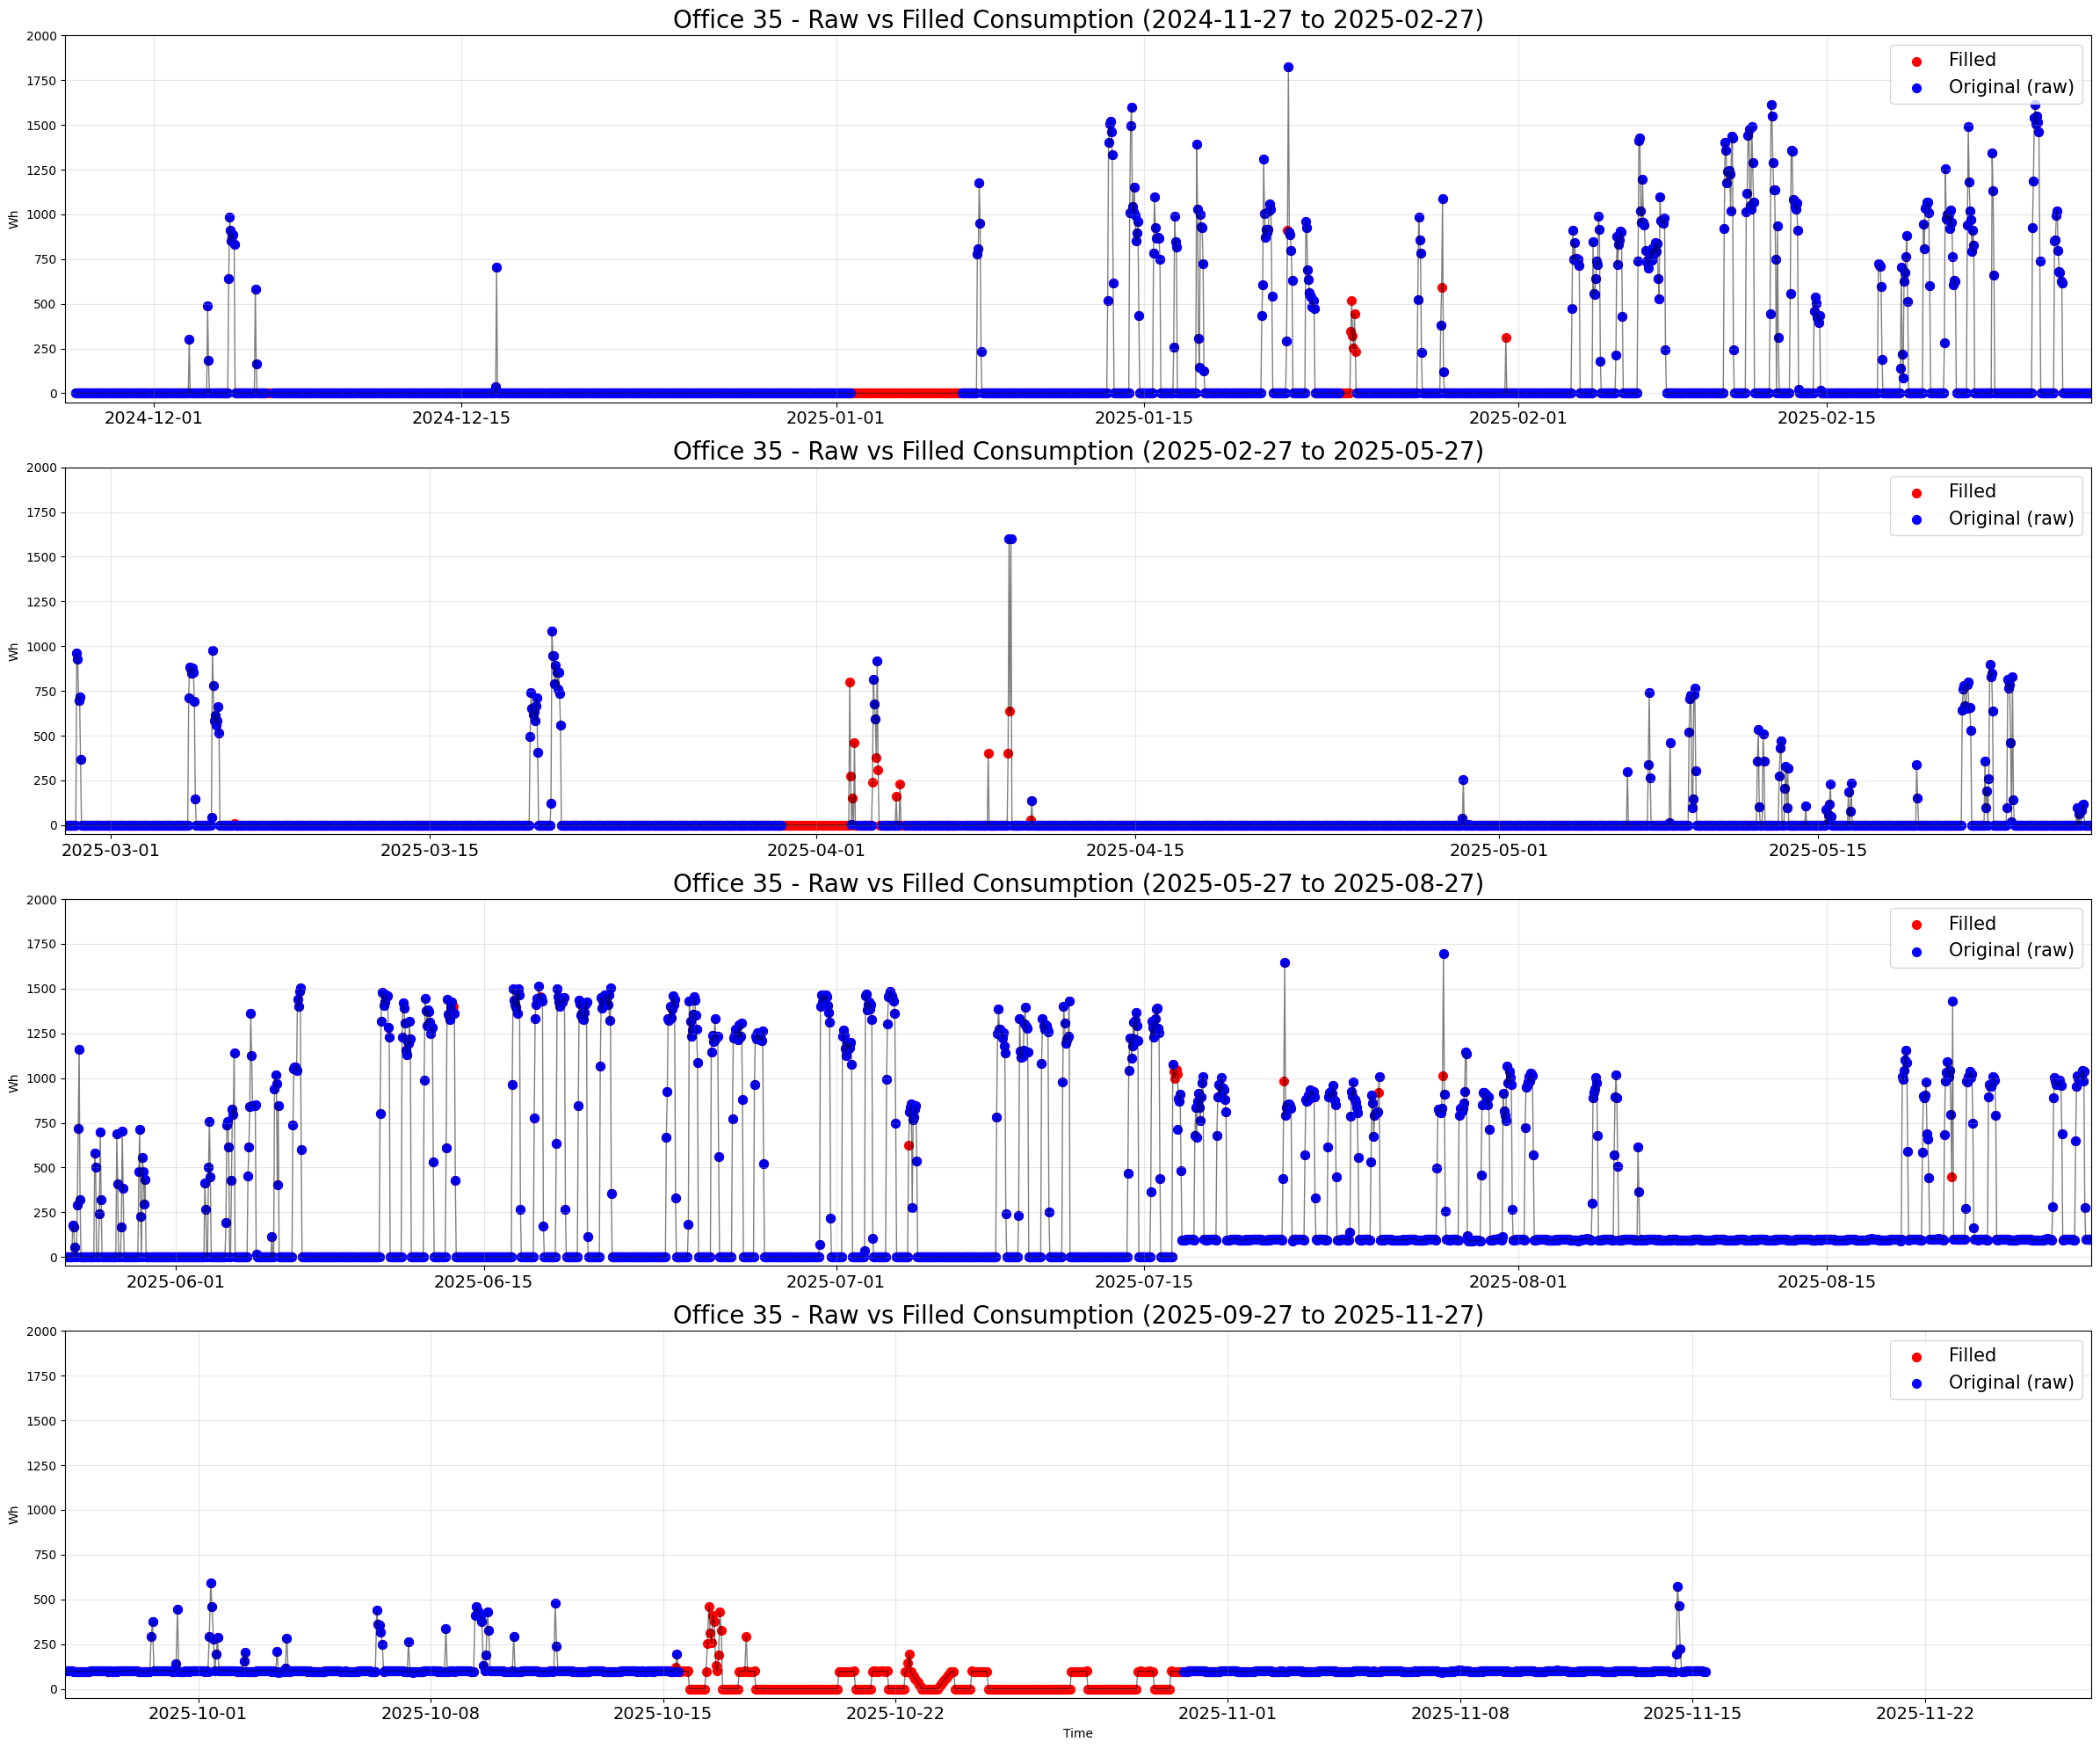

In [40]:
fig, axes = plt.subplots(len(date_ranges), 1, figsize=(24, 5 * len(date_ranges)))

for ax, (start, end) in zip(axes, date_ranges):
    ax.plot(df.index, df['consumption_full'], color='black', linewidth=1, alpha=0.5)
    ax.scatter(df.index, df['consumption_full'], color='red', s=50, alpha=1, label='Filled')
    ax.scatter(df.index, df['consumption'], color='blue', s=50, alpha=1, label='Original (raw)')
    ax.set_xlim(pd.to_datetime(start), pd.to_datetime(end))
    ax.set_ylim(-50, 2000)
    ax.set_title(f"Office 35 - Raw vs Filled Consumption ({start} to {end})", fontsize=20)
    ax.set_ylabel("Wh")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=15)
    ax.tick_params(axis="x", labelsize=14)

axes[-1].set_xlabel("Time")
plt.tight_layout()
plt.show()

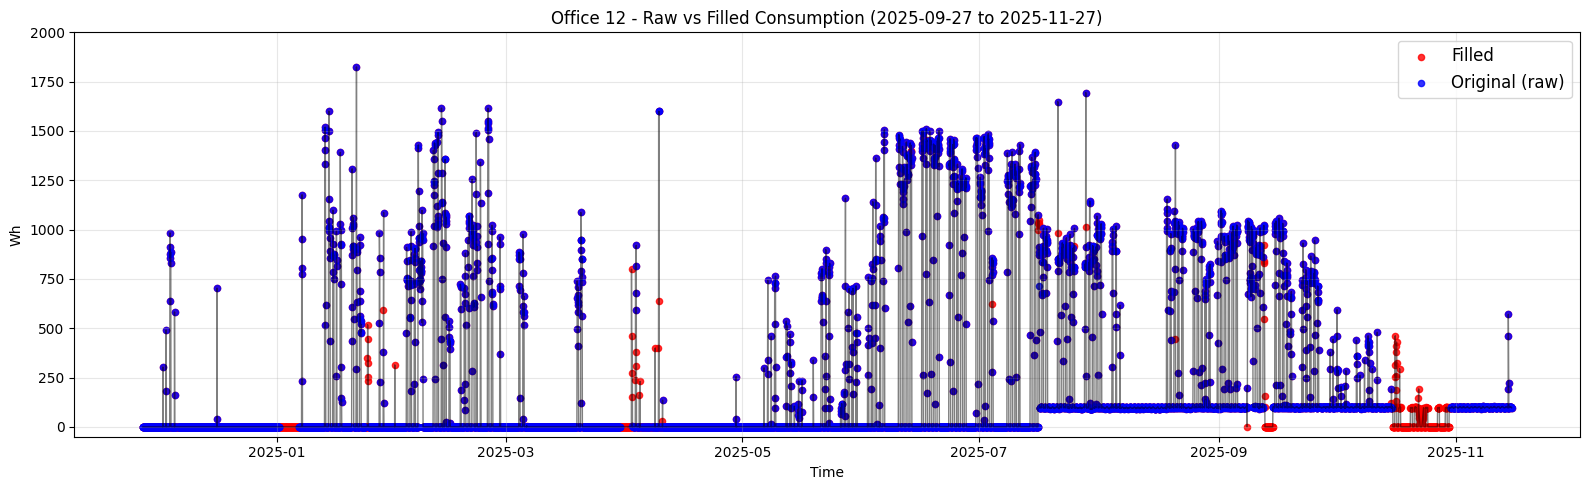

In [41]:
fig = plt.figure(figsize=(16, 5))

plt.plot(df.index, df['consumption_full'], color='black', linewidth=1, alpha=0.5)
plt.scatter(df.index, df['consumption_full'], color='red', s=20, alpha=0.8, label='Filled')
plt.scatter(df.index, df['consumption'], color='blue', s=20, alpha=0.8, label='Original (raw)')
plt.ylim(-50, 2000)
plt.title(f"Office 12 - Raw vs Filled Consumption ({start} to {end})")
plt.ylabel("Wh")
plt.grid(True, alpha=0.3)
plt.legend(fontsize=12)

plt.xlabel("Time")
plt.tight_layout()
plt.show()

### Save

In [ ]:
#df.to_excel("../data/consumption35_filled.xlsx")
print("Saved consumption35_filled.xlsx")

Saved consumption35_filled.xlsx
